Task 11: Composite task, a computer-vision system

In [2]:
import cv2, numpy as np, matplotlib.pyplot as plt, csv, json, time
from pathlib import Path
from collections import Counter

VIDEO = Path("data") / "task10_motion.mp4"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

# --- settings (Task 10 choice + new filters) ---
MAX_SIDE, BLUR = 960, 5
HISTORY, VAR_THR = 100, 16
K_OPEN, K_CLOSE = 5, 15
MIN_AREA, MAX_AREA = 80, 20000          # px^2 at 540x960
MIN_SOLIDITY = 0.7
ASPECT_MIN, ASPECT_MAX = 0.4, 2.5
K_O = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_OPEN, K_OPEN))
K_C = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_CLOSE, K_CLOSE))

def preprocess(frame):
    """Resize (longer side = MAX_SIDE) and blur."""
    h, w = frame.shape[:2]; s = MAX_SIDE / max(h, w)
    small = cv2.resize(frame, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return small, cv2.GaussianBlur(small, (BLUR, BLUR), 0)

def clean(raw):
    """Keep MOG2 foreground (255), drop shadows (127), then open + close."""
    m = np.where(raw == 255, 255, 0).astype(np.uint8)
    return cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, K_O), cv2.MORPH_CLOSE, K_C)

def blob_features(c):
    area = cv2.contourArea(c)
    x, y, w, h = cv2.boundingRect(c)
    hull_area = cv2.contourArea(cv2.convexHull(c))
    return dict(x=x, y=y, w=w, h=h, area=area, cx=x + w / 2, cy=y + h / 2,
                solidity=area / hull_area if hull_area > 0 else 0.0, aspect=w / h)

def reject_reason(b):
    """None = keep; otherwise the first failed test."""
    if b["area"] < MIN_AREA: return "small"
    if b["area"] > MAX_AREA: return "large"
    if b["solidity"] < MIN_SOLIDITY: return "solidity"
    if not ASPECT_MIN <= b["aspect"] <= ASPECT_MAX: return "aspect"
    return None

def find_blobs(mask):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    blobs = [blob_features(c) for c in cnts]
    for b in blobs: b["reason"] = reject_reason(b)
    return blobs

Cell 2 (run over the video, collect statistics, sample frames):

frames: 992
blobs by outcome: {'small': 429, 'solidity': 102, 'aspect': 45, 'kept': 557, 'large': 38}
mean ms per stage: {'read': 17.47, 'preprocess': 3.32, 'mog2': 6.15, 'morphology': 9.83, 'contours+filter': 0.4} | total 37.2 ms
count per frame  Task10 rule: max 14, mean 0.75 | filtered: max 8, mean 0.56


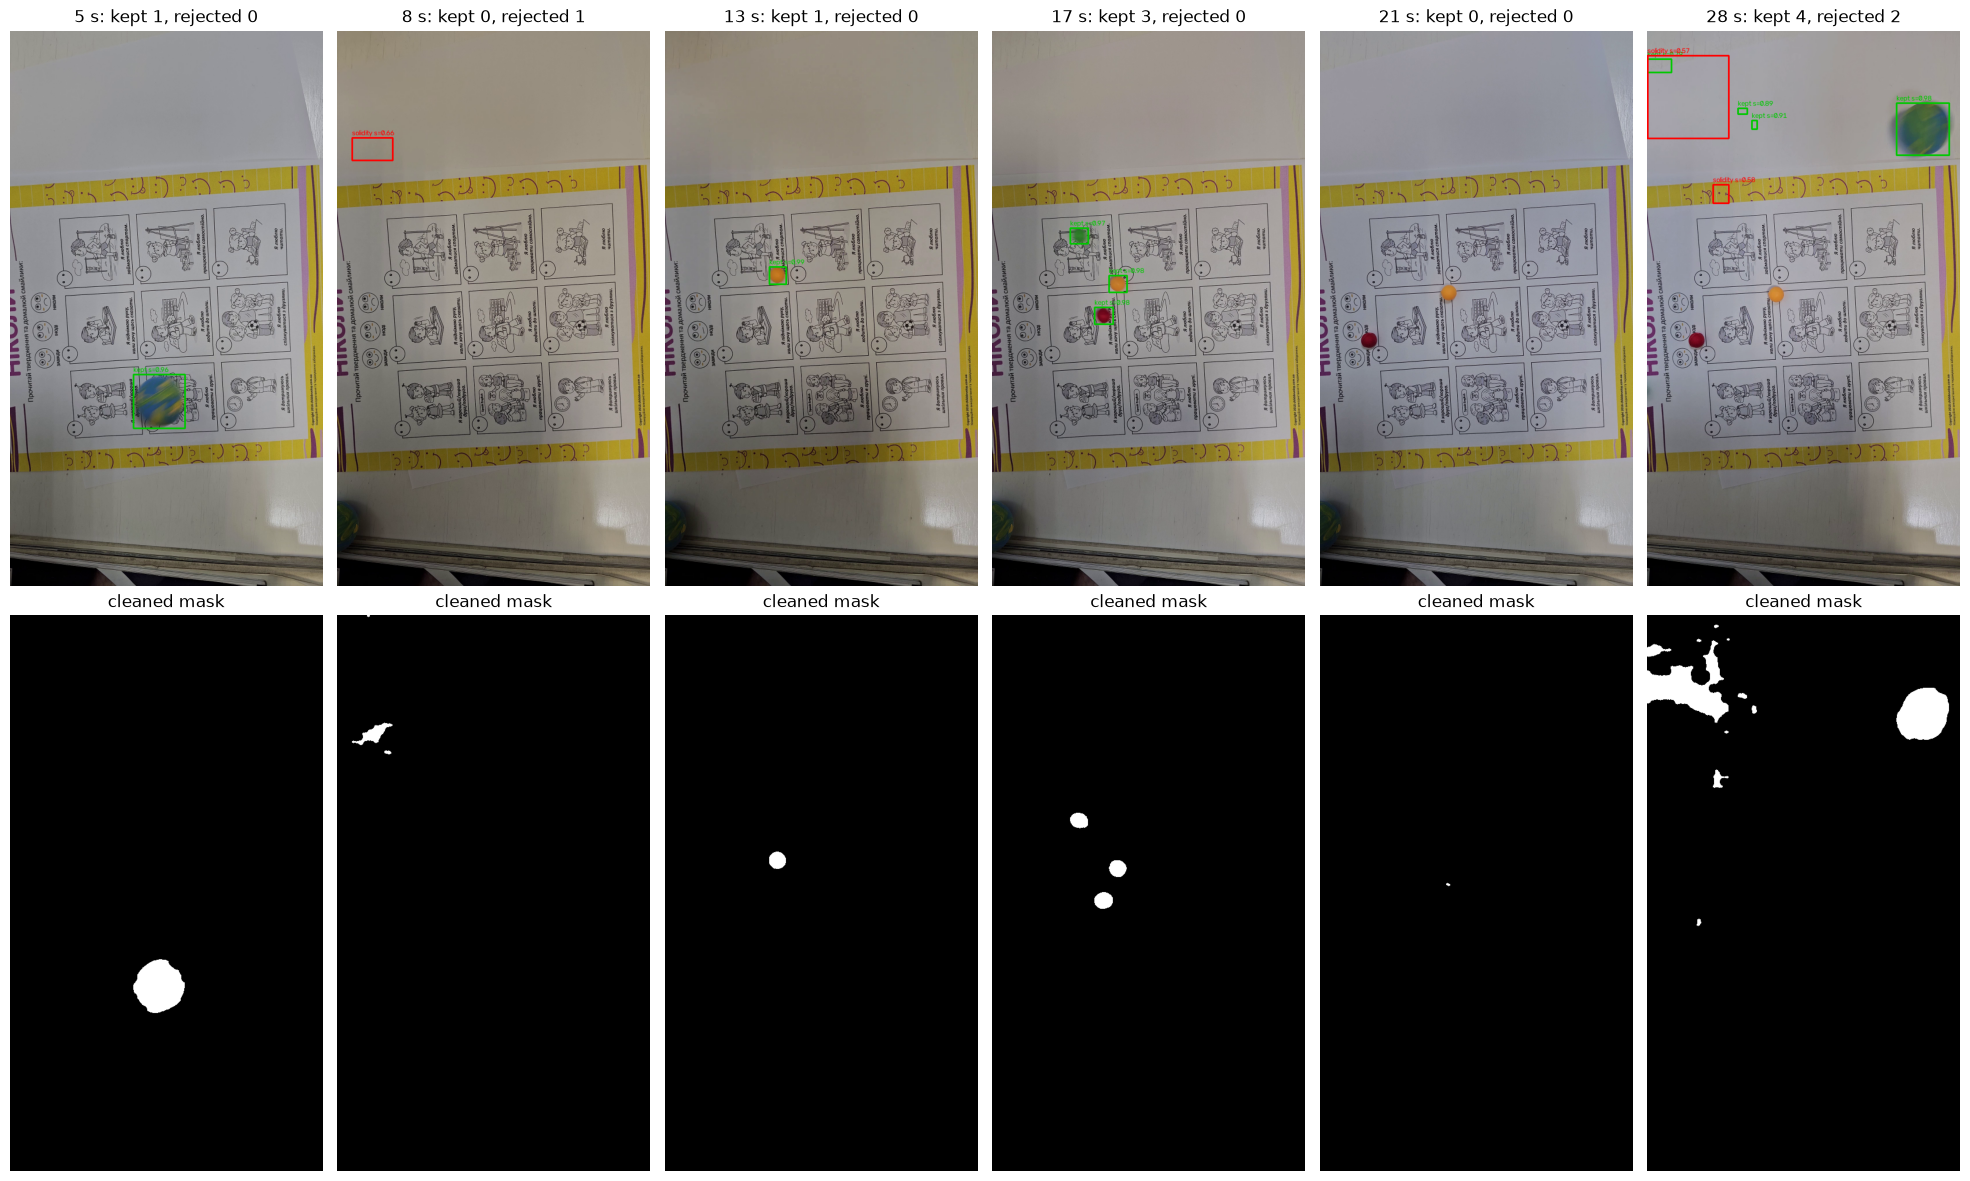

In [3]:
SAMPLE_TIMES = [5, 8, 13, 17, 21, 28]   # moving ball, lighting burst, resting ball, 3 objects, green ball, burst + big ball
sub = cv2.createBackgroundSubtractorMOG2(history=HISTORY, varThreshold=VAR_THR, detectShadows=True)
cap = cv2.VideoCapture(str(VIDEO)); assert cap.isOpened()
fps = cap.get(cv2.CAP_PROP_FPS)
sample_nos = {int(t * fps): t for t in SAMPLE_TIMES}

reasons = Counter()
stage_ms = {k: [] for k in ["read", "preprocess", "mog2", "morphology", "contours+filter"]}
rows, snaps, i = [], {}, 0
while True:
    t0 = time.perf_counter(); ok, f = cap.read(); t1 = time.perf_counter()
    if not ok: break
    small, blur_c = preprocess(f);   t2 = time.perf_counter()
    raw = sub.apply(blur_c);         t3 = time.perf_counter()
    mask = clean(raw);               t4 = time.perf_counter()
    blobs = find_blobs(mask);        t5 = time.perf_counter()
    for k, (a, b) in zip(stage_ms, [(t0, t1), (t1, t2), (t2, t3), (t3, t4), (t4, t5)]):
        stage_ms[k].append((b - a) * 1000)

    n_task10 = sum(b["area"] >= MIN_AREA for b in blobs)          # Task 10 rule
    n_kept = sum(b["reason"] is None for b in blobs)               # new filter
    reasons.update(b["reason"] or "kept" for b in blobs if b["area"] >= MIN_AREA or b["reason"] == "small")
    rows.append([i, round(i / fps, 3), n_task10, n_kept])
    if i in sample_nos: snaps[i] = (small.copy(), mask.copy(), blobs)
    i += 1
cap.release()

print(f"frames: {i}")
print("blobs by outcome:", dict(reasons))
print("mean ms per stage:", {k: round(float(np.mean(v)), 2) for k, v in stage_ms.items()},
      f"| total {sum(np.mean(v) for v in stage_ms.values()):.1f} ms")
n10 = np.array([r[2] for r in rows]); nk = np.array([r[3] for r in rows])
print(f"count per frame  Task10 rule: max {n10.max()}, mean {n10.mean():.2f} | "
      f"filtered: max {nk.max()}, mean {nk.mean():.2f}")
with open(RESULTS / "task11_step2_counts.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["frame", "time_s", "n_task10_rule", "n_filtered"]); w.writerows(rows)

# sample frames: kept (green) vs rejected (red, with reason); specks < MIN_AREA not drawn
fig, ax = plt.subplots(2, len(SAMPLE_TIMES), figsize=(3.3 * len(SAMPLE_TIMES), 12))
for j, k in enumerate(sorted(snaps)):
    small, mask, blobs = snaps[k]; vis = small.copy()
    for b in blobs:
        if b["reason"] == "small": continue
        col = (0, 200, 0) if b["reason"] is None else (0, 0, 255)
        cv2.rectangle(vis, (b["x"], b["y"]), (b["x"] + b["w"], b["y"] + b["h"]), col, 2)
        label = "kept" if b["reason"] is None else b["reason"]
        cv2.putText(vis, f"{label} s={b['solidity']:.2f}", (b["x"], max(b["y"] - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, col, 1, cv2.LINE_AA)
    kept = sum(b["reason"] is None for b in blobs); rej = sum(b["reason"] not in (None, "small") for b in blobs)
    ax[0, j].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(f"{sample_nos[k]} s: kept {kept}, rejected {rej}")
    ax[1, j].imshow(mask, cmap="gray"); ax[1, j].set_title("cleaned mask")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task11_step2_filtering.png", dpi=80); plt.show()

Steps 3–4: The tracker and the full system script

In [4]:
"""Task 11: video -> preprocessing -> motion detection (MOG2) -> contours -> filtering -> tracking -> visualisation.
Usage (venv active, project folder):
    python task11_system.py             live window (p = pause, q = quit)
    python task11_system.py --no-show   no window
"""
import sys, csv, json, time, math
from pathlib import Path
from collections import deque
import cv2, numpy as np

VIDEO   = Path("data") / "task10_motion.mp4"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

# ---- settings ----
MAX_SIDE, BLUR = 960, 5
HISTORY, VAR_THR = 100, 16
K_OPEN, K_CLOSE = 5, 15
MIN_AREA, MAX_AREA, MIN_SOLIDITY = 80, 20000, 0.7
ASPECT_MIN, ASPECT_MAX = 0.4, 2.5
MAX_DIST, MAX_MISSED, MIN_HITS, TRAIL = 60, 15, 5, 30
K_O = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_OPEN, K_OPEN))
K_C = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_CLOSE, K_CLOSE))
FONT = cv2.FONT_HERSHEY_SIMPLEX

# ---- 1) preprocessing, 2) motion mask, 3) contours, 4) filtering ----
def preprocess(frame):
    h, w = frame.shape[:2]; s = MAX_SIDE / max(h, w)
    small = cv2.resize(frame, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return small, cv2.GaussianBlur(small, (BLUR, BLUR), 0)

def clean(raw):
    m = np.where(raw == 255, 255, 0).astype(np.uint8)
    return cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, K_O), cv2.MORPH_CLOSE, K_C)

def find_objects(mask):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in cnts:
        area = cv2.contourArea(c)
        if not MIN_AREA <= area <= MAX_AREA: continue
        x, y, w, h = cv2.boundingRect(c)
        hull = cv2.contourArea(cv2.convexHull(c))
        if hull <= 0 or area / hull < MIN_SOLIDITY: continue
        if not ASPECT_MIN <= w / h <= ASPECT_MAX: continue
        out.append(dict(x=x, y=y, w=w, h=h, area=area, cx=x + w / 2, cy=y + h / 2))
    return out

# ---- 5) tracking ----
class CentroidTracker:
    def __init__(self, max_dist, max_missed, min_hits):
        self.max_dist, self.max_missed, self.min_hits = max_dist, max_missed, min_hits
        self.tracks, self.next_id = [], 1

    def update(self, dets):
        pairs = sorted((math.hypot(t["cx"] - d["cx"], t["cy"] - d["cy"]), ti, di)
                       for ti, t in enumerate(self.tracks) for di, d in enumerate(dets))
        used_t, used_d = set(), set()
        for dist, ti, di in pairs:                                   # greedy: closest pairs first
            if dist > self.max_dist: break
            if ti in used_t or di in used_d: continue
            used_t.add(ti); used_d.add(di)
            t, d = self.tracks[ti], dets[di]
            t.update({k: d[k] for k in ("x", "y", "w", "h", "area", "cx", "cy")})
            t["hits"] += 1; t["missed"] = 0; t["trail"].append((int(d["cx"]), int(d["cy"])))
            if t["id"] is None and t["hits"] >= self.min_hits:       # confirm -> give a visible ID
                t["id"] = self.next_id; self.next_id += 1
        for ti, t in enumerate(self.tracks):
            if ti not in used_t: t["missed"] += 1
        self.tracks = [t for t in self.tracks                        # tentative: 1 miss, confirmed: MAX_MISSED
                       if t["missed"] <= (self.max_missed if t["id"] is not None else 1)]
        for di, d in enumerate(dets):
            if di not in used_d:
                t = {k: d[k] for k in ("x", "y", "w", "h", "area", "cx", "cy")}
                t.update(id=None, hits=1, missed=0, trail=deque([(int(d["cx"]), int(d["cy"]))], maxlen=TRAIL))
                self.tracks.append(t)
        return [t for t in self.tracks if t["id"] is not None and t["missed"] == 0]

# ---- 6) visualisation ----
def id_colour(i):
    hsv = np.uint8([[[(i * 47) % 180, 230, 255]]])
    return tuple(int(c) for c in cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)[0, 0])

def text(img, s, org, col, scale=0.4):
    cv2.putText(img, s, org, FONT, scale, (0, 0, 0), 3, cv2.LINE_AA)   # dark outline for readability
    cv2.putText(img, s, org, FONT, scale, col, 1, cv2.LINE_AA)

def draw_object(img, o):
    col = id_colour(o["id"]); x, y, w, h = o["x"], o["y"], o["w"], o["h"]
    cv2.rectangle(img, (x, y), (x + w, y + h), col, 2)
    if len(o["trail"]) > 1: cv2.polylines(img, [np.array(o["trail"], np.int32)], False, col, 2)
    lines = [f"Object ID: {o['id']}", f"X: {x}", f"Y: {y}", f"Width: {w}", f"Height: {h}", f"Area: {int(o['area'])}"]
    tx = x + w + 5 if x + w + 115 < img.shape[1] else max(x - 115, 0)
    for k, s in enumerate(lines): text(img, s, (tx, max(y, 10) + 12 + 13 * k), col)

def draw_panel(img, objs, fps):
    a = [o["area"] for o in objs]
    lines = [f"Objects in frame: {len(objs)}",
             f"Mean area: {np.mean(a):.0f}" if a else "Mean area: -",
             f"Max area: {max(a):.0f}" if a else "Max area: -",
             f"Min area: {min(a):.0f}" if a else "Min area: -",
             f"FPS: {fps:.1f}"]
    over = img.copy(); cv2.rectangle(over, (0, 0), (215, 20 * len(lines) + 8), (0, 0, 0), -1)
    cv2.addWeighted(over, 0.55, img, 0.45, 0, img)
    for k, s in enumerate(lines): text(img, s, (8, 20 + 20 * k), (255, 255, 255), 0.55)

# ---- main loop ----
def main(show=True):
    cap = cv2.VideoCapture(str(VIDEO))
    if not cap.isOpened(): sys.exit(f"Cannot open {VIDEO}")
    fps_v = cap.get(cv2.CAP_PROP_FPS) or 30
    sub = cv2.createBackgroundSubtractorMOG2(history=HISTORY, varThreshold=VAR_THR, detectShadows=True)
    tracker = CentroidTracker(MAX_DIST, MAX_MISSED, MIN_HITS)
    writer, frame_rows, obj_rows, ms_hist, idx = None, [], [], deque(maxlen=30), 0
    if show: cv2.namedWindow("Task 11", cv2.WINDOW_NORMAL)

    while True:
        t0 = time.perf_counter()
        ok, f = cap.read()
        if not ok: break
        small, blur_c = preprocess(f)                       # 1 preprocessing
        mask = clean(sub.apply(blur_c))                     # 2 motion detection + morphology
        dets = find_objects(mask)                           # 3 contours + 4 filtering
        objs = tracker.update(dets)                         # 5 tracking
        fps_now = 1000 / np.mean(ms_hist) if ms_hist else 0.0
        vis = small.copy()                                  # 6 visualisation
        for o in objs: draw_object(vis, o)
        draw_panel(vis, objs, fps_now)
        if writer is None:
            writer = cv2.VideoWriter(str(RESULTS / "task11_output.mp4"), cv2.VideoWriter_fourcc(*"mp4v"),
                                     fps_v, (vis.shape[1], vis.shape[0]))
        writer.write(vis)
        if show:
            cv2.imshow("Task 11", vis)
            key = cv2.waitKey(1) & 0xFF
            if key == ord("p"):
                while (cv2.waitKey(30) & 0xFF) != ord("p"): pass
            elif key in (ord("q"), 27): break
        ms = (time.perf_counter() - t0) * 1000; ms_hist.append(ms)

        a = [o["area"] for o in objs]; ts = round(idx / fps_v, 3)
        frame_rows.append([idx, ts, len(objs), round(float(np.mean(a)), 1) if a else "", int(max(a)) if a else "",
                           int(min(a)) if a else "", round(ms, 2), round(fps_now, 1)])
        for o in objs:
            obj_rows.append([idx, ts, o["id"], o["x"], o["y"], o["w"], o["h"], int(o["area"]), int(o["cx"]), int(o["cy"])])
        idx += 1

    cap.release(); writer.release(); cv2.destroyAllWindows()
    with open(RESULTS / "task11_frames.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["frame", "time_s", "n_objects", "mean_area", "max_area", "min_area", "frame_ms", "fps"])
        w.writerows(frame_rows)
    with open(RESULTS / "task11_objects.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["frame", "time_s", "id", "x", "y", "w", "h", "area", "cx", "cy"]); w.writerows(obj_rows)

    tracks = {}
    for r in obj_rows: tracks.setdefault(r[2], []).append(r)
    with open(RESULTS / "task11_tracks.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["id", "first_s", "last_s", "frames_seen", "mean_area"])
        for i, rs in sorted(tracks.items()):
            w.writerow([i, rs[0][1], rs[-1][1], len(rs), round(float(np.mean([r[7] for r in rs])), 1)])
    ms_all = np.array([r[6] for r in frame_rows]); n = np.array([r[2] for r in frame_rows])
    summary = dict(frames=len(frame_rows), ids_created=tracker.next_id - 1, max_objects=int(n.max()),
                   mean_objects=round(float(n.mean()), 2), mean_frame_ms=round(float(ms_all.mean()), 1),
                   system_fps=round(1000 / float(ms_all.mean()), 1))
    (RESULTS / "task11_summary.json").write_text(json.dumps(summary, indent=2))
    print(summary)
    for i, rs in sorted(tracks.items()):
        print(f"  ID {i:2d}: {rs[0][1]:5.1f}-{rs[-1][1]:5.1f} s, {len(rs):4d} frames, mean area {np.mean([r[7] for r in rs]):6.0f}")

if __name__ == "__main__":
    main(show="--no-show" not in sys.argv)

{'frames': 992, 'ids_created': 15, 'max_objects': 3, 'mean_objects': 0.41, 'mean_frame_ms': 69.9, 'system_fps': 14.3}
  ID  1:   4.7-  6.0 s,   37 frames, mean area   4630
  ID  2:   6.7-  7.0 s,   10 frames, mean area   1387
  ID  3:   7.7-  7.8 s,    2 frames, mean area    250
  ID  4:   7.9-  8.1 s,    3 frames, mean area    678
  ID  5:  10.2- 10.2 s,    1 frames, mean area   1793
  ID  6:  11.0- 15.8 s,  132 frames, mean area    563
  ID  7:  11.1- 11.4 s,   11 frames, mean area    548
  ID  8:  16.7- 18.9 s,   53 frames, mean area    551
  ID  9:  16.9- 17.7 s,   23 frames, mean area    618
  ID 10:  17.0- 21.1 s,   91 frames, mean area    424
  ID 11:  21.3- 21.8 s,   16 frames, mean area    528
  ID 12:  23.0- 23.1 s,    5 frames, mean area    465
  ID 13:  23.0- 23.1 s,    2 frames, mean area    354
  ID 14:  25.6- 25.8 s,    5 frames, mean area   4251
  ID 15:  27.5- 28.1 s,   19 frames, mean area   5537


Step 5: Evaluation, the effect of each stage

{'version': 'Task 10 rule (area only)', 'max_count': 14, 'mean_count': 0.75, 'detects_motion': '4/7', 'false_alarm_when_still': '2/10', 'correct_count_when_moving': '2/7', 'mae_vs_moving': 0.65}
{'version': '+ shape filter', 'max_count': 8, 'mean_count': 0.56, 'detects_motion': '2/7', 'false_alarm_when_still': '2/10', 'correct_count_when_moving': '0/7', 'mae_vs_moving': 0.65}
{'version': '+ tracking (Task 11)', 'max_count': 3, 'mean_count': 0.41, 'detects_motion': '2/7', 'false_alarm_when_still': '2/10', 'correct_count_when_moving': '1/7', 'mae_vs_moving': 0.59}


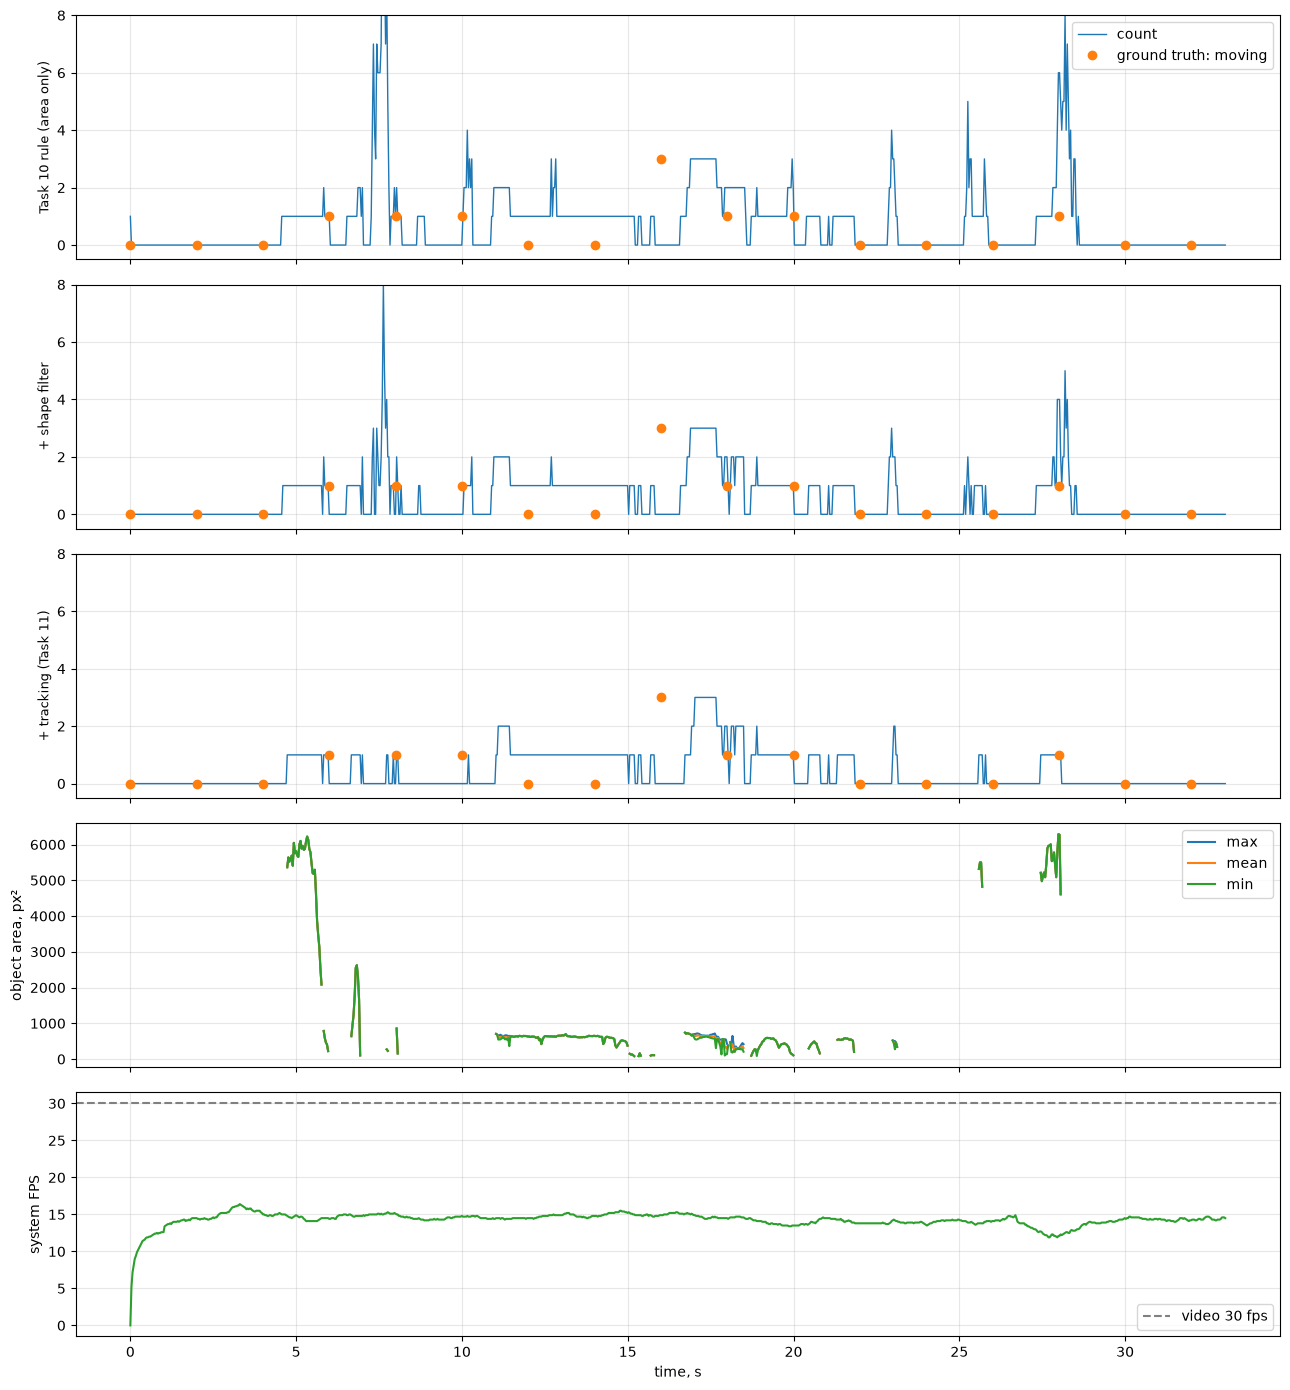

In [5]:
import csv
GT = {0: (0, 0), 2: (0, 0), 4: (0, 0), 6: (1, 1), 8: (1, 1), 10: (1, 1), 12: (1, 0), 14: (1, 0), 16: (1, 3),
      18: (2, 1), 20: (2, 1), 22: (2, 0), 24: (2, 0), 26: (2, 0), 28: (3, 1), 30: (2, 0), 32: (2, 0)}   # (visible, moving), as in Task 10
WIN = 0.2

def read_csv(path):
    with open(path) as f: rows = list(csv.DictReader(f))
    return {k: np.array([float(r[k]) if r[k] != "" else np.nan for r in rows]) for k in rows[0]}

s2 = read_csv(RESULTS / "task11_step2_counts.csv")
fr = read_csv(RESULTS / "task11_frames.csv")
variants = {"Task 10 rule (area only)": (s2["time_s"], s2["n_task10_rule"]),
            "+ shape filter":           (s2["time_s"], s2["n_filtered"]),
            "+ tracking (Task 11)":     (fr["time_s"], fr["n_objects"])}

ts = np.array(sorted(GT)); gt_mov = np.array([GT[t][1] for t in ts]); moving = gt_mov > 0
table = []
for name, (t, c) in variants.items():
    pred = np.array([np.median(c[(t >= s - WIN) & (t <= s + WIN)]) for s in ts]).round().astype(int)
    table.append(dict(version=name, max_count=int(np.nanmax(c)), mean_count=round(float(np.nanmean(c)), 2),
                      detects_motion=f"{int(np.sum(pred[moving] > 0))}/{moving.sum()}",
                      false_alarm_when_still=f"{int(np.sum(pred[~moving] > 0))}/{(~moving).sum()}",
                      correct_count_when_moving=f"{int(np.sum(pred[moving] == gt_mov[moving]))}/{moving.sum()}",
                      mae_vs_moving=round(float(np.mean(np.abs(pred - gt_mov))), 2)))
for r in table: print(r)
with open(RESULTS / "task11_summary.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(table[0])); w.writeheader(); w.writerows(table)

fig, ax = plt.subplots(5, 1, figsize=(13, 14), sharex=True)
for a, (name, (t, c)) in zip(ax[:3], variants.items()):
    a.plot(t, c, lw=1, label="count"); a.plot(ts, gt_mov, "o", color="tab:orange", label="ground truth: moving")
    a.set_ylabel(name, fontsize=9); a.set_ylim(-0.5, 8); a.grid(alpha=0.3)
ax[0].legend(loc="upper right")
ax[3].plot(fr["time_s"], fr["max_area"], label="max"); ax[3].plot(fr["time_s"], fr["mean_area"], label="mean")
ax[3].plot(fr["time_s"], fr["min_area"], label="min"); ax[3].set_ylabel("object area, px²"); ax[3].legend(); ax[3].grid(alpha=0.3)
ax[4].plot(fr["time_s"], fr["fps"], color="tab:green"); ax[4].axhline(30, color="gray", ls="--", label="video 30 fps")
ax[4].set_ylabel("system FPS"); ax[4].set_xlabel("time, s"); ax[4].legend(); ax[4].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS / "task11_evaluation.png", dpi=100); plt.show()